Posição do poço = 5 10
Permeabilidade no bloco do poço = 156.76208937356003 mD
Pressão inicial = 20.684 MPa
Pressão final = 17.88426479232085 MPa
Pwf = 15.0 MPa
Vazão final = -0.018302836787737663 m³/s


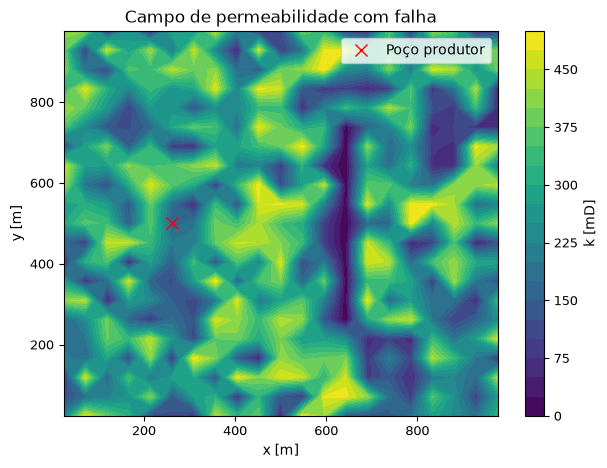

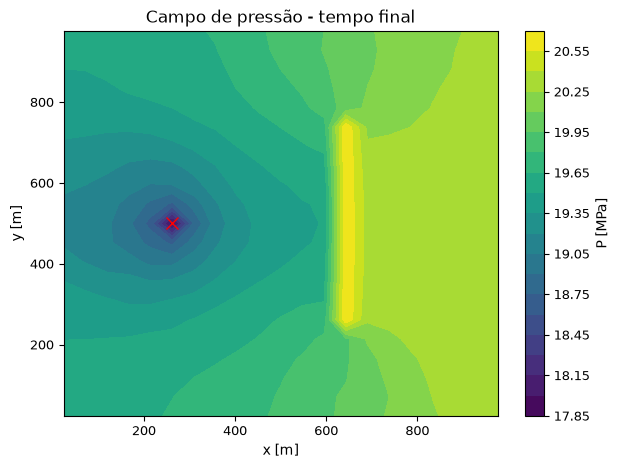

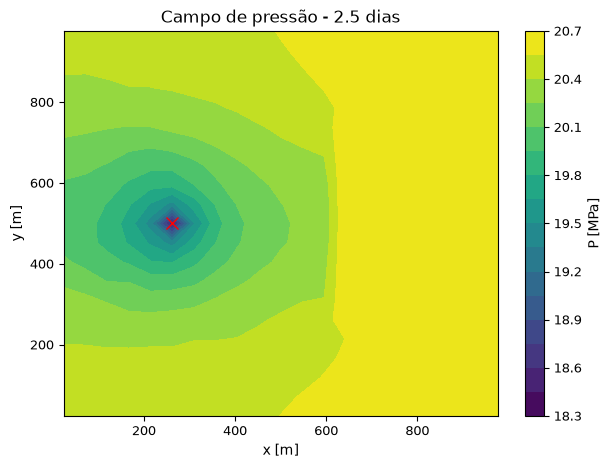

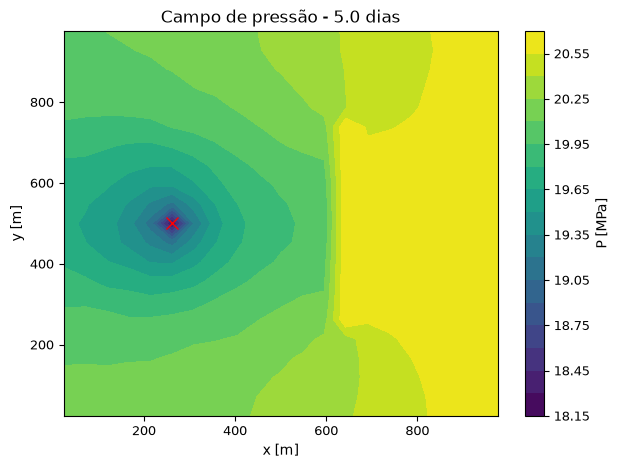

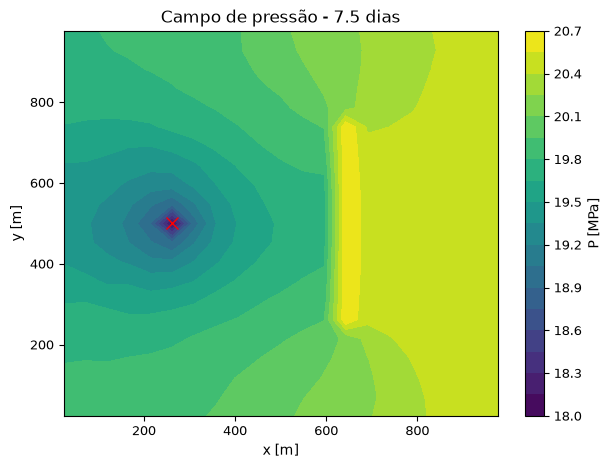

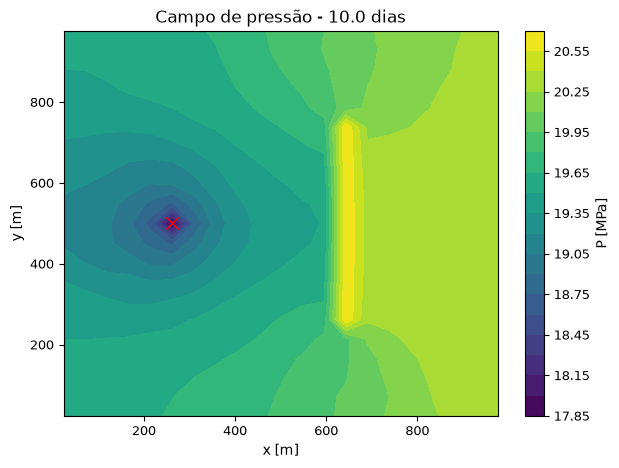

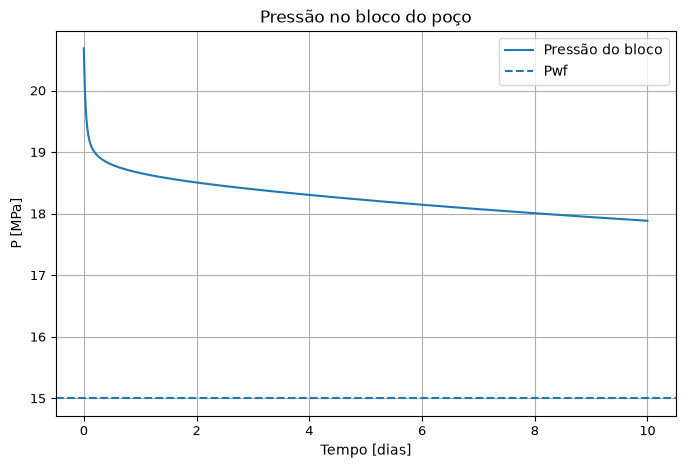

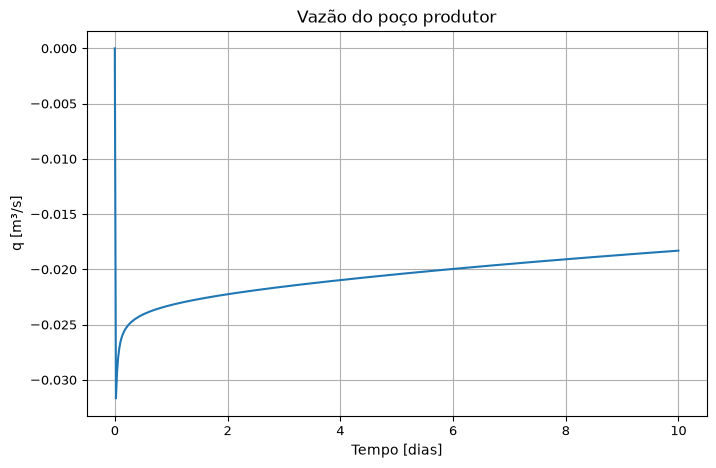

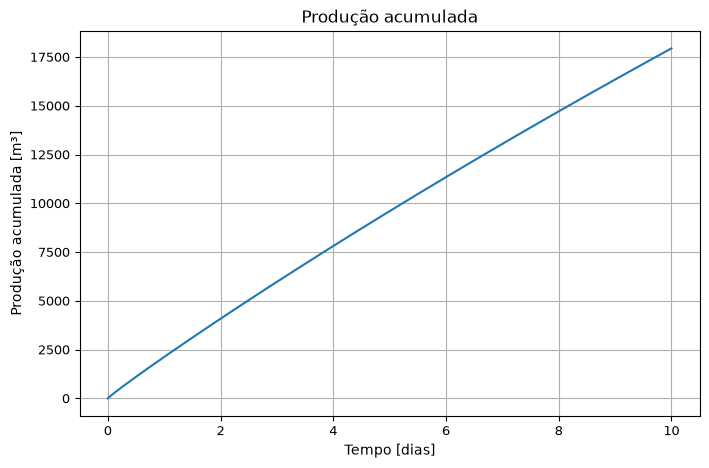

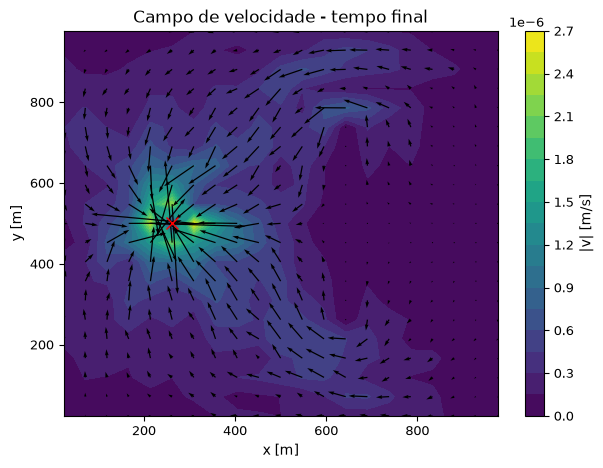

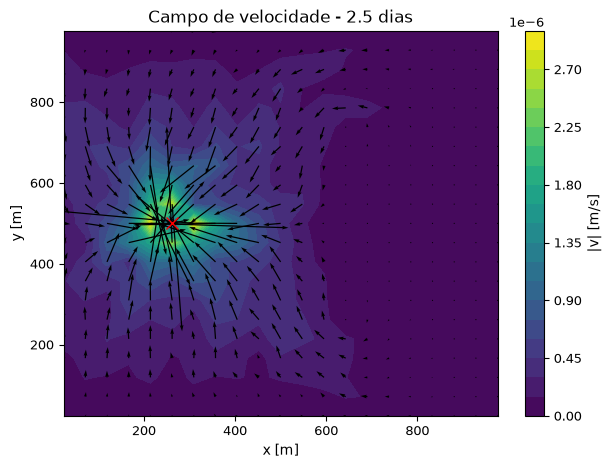

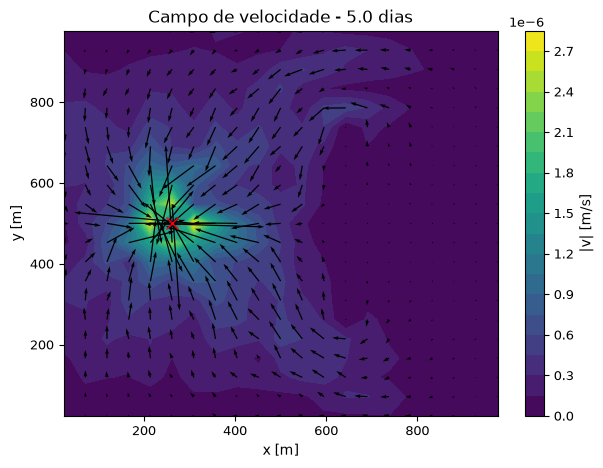

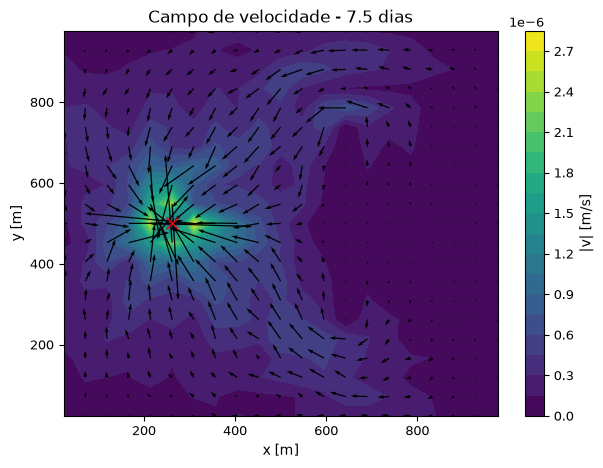

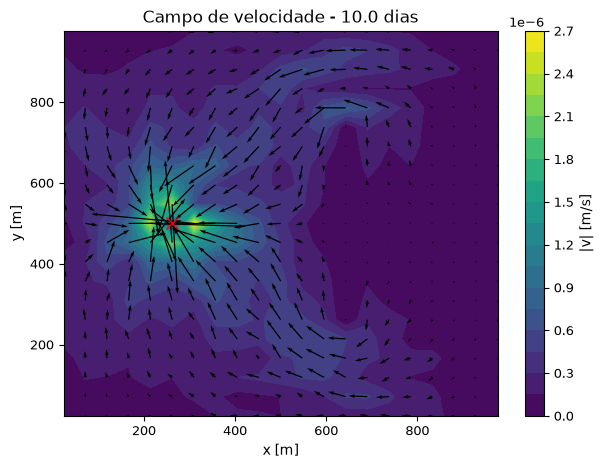

In [1]:
from pathlib import Path
import sys

ROOT = next(path for path in (Path.cwd(), *Path.cwd().parents) if (path / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
RESULTS_DIR = ROOT / "results"
RESULTS_DIR.mkdir(exist_ok=True)

import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"font.family": "sans-serif", "font.size": 10, "axes.titlesize": 12, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9, "legend.fontsize": 10, "figure.facecolor": "white", "axes.facecolor": "white", "savefig.facecolor": "white"})

from matplotlib.animation import FuncAnimation
from IPython.display import HTML

from mdf.implicita_2d import implicita_2d
from mdf.permeabilidade2d import carregar_permeabilidade
from mdf.falha import aplicar_falha
from mdf.velocidade2d import calcular_velocidade



_figura_id = 0
def salvar_e_mostrar():
    global _figura_id
    _figura_id += 1
    plt.savefig(RESULTS_DIR / f"falha_produtor_{_figura_id:02d}.pdf", dpi=180, bbox_inches="tight")
    plt.show()

# parâmetros

p0 = 20.684e6
pwf = 15.0e6

Lx = 1000.0
Ly = 1000.0

h = 30.0
rw = 0.10

phi = 0.22
ct = 3.046e-9
mu = 1.0e-3

t_d = 10
t_final = t_d * 86400


# malha

nx = 21
ny = 21
nt = 500

dx = Lx / nx
dy = Ly / ny


# permeabilidade

k_base_mD = carregar_permeabilidade(ROOT / "data" / "permeabilidade.csv")

# falha

k_mD = aplicar_falha(k_base_mD,i_inicio=13,i_fim=13, j_inicio=5,j_fim=15,k_falha=1e-3)
k = k_mD * 9.869233e-16

# posição do poço
iw = 5
jw = 10

# solução

x, y, t, P, q_poco = implicita_2d(p0,pwf,rw,h,Lx,Ly,k,phi,ct,mu,t_final,nx,ny,nt,iw=iw,jw=jw)

print("Posição do poço =", iw, jw)
print("Permeabilidade no bloco do poço =", k_mD[jw, iw], "mD")
print("Pressão inicial =", P[0, jw, iw] / 1e6, "MPa")
print("Pressão final =", P[-1, jw, iw] / 1e6, "MPa")
print("Pwf =", pwf / 1e6, "MPa")
print("Vazão final =", q_poco[-1], "m³/s")


# malha para gráficos

X, Y = np.meshgrid(x, y)

# mapa de permeabilidade com a falha

plt.figure(figsize=(7, 5))
mapa = plt.contourf(X,Y,k_mD,levels=20, cmap="viridis")
plt.colorbar(mapa,label="k [mD]")
plt.plot(x[iw],y[jw],"rx",markersize=8,label="Poço produtor")
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.title("Campo de permeabilidade com falha")
plt.legend()

salvar_e_mostrar()

# pressão final

plt.figure(figsize=(7, 5))
contorno = plt.contourf(X,Y,P[-1] / 1e6,levels=20, cmap="viridis")
plt.colorbar(contorno,label="P [MPa]")
plt.plot(x[iw],y[jw],"rx",markersize=8)
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.title("Campo de pressão - tempo final")

salvar_e_mostrar()


# pressão em diferentes tempos
tempos = np.linspace(t_d / 4,t_d,4)
for tempo in tempos:
    indice = np.argmin(np.abs(t - tempo * 86400))
    plt.figure(figsize=(7, 5))
    contorno = plt.contourf(X,Y,P[indice] / 1e6,levels=20, cmap="viridis")
    plt.colorbar(contorno,label="P [MPa]")
    plt.plot(x[iw],y[jw],"rx",markersize=8)
    plt.xlabel("x [m]")
    plt.ylabel("y [m]")
    plt.title(f"Campo de pressão - {tempo:.1f} dias")

    salvar_e_mostrar()


# pressão no bloco do poço
plt.figure(figsize=(8, 5))
plt.plot(t / 86400,P[:, jw, iw] / 1e6,label="Pressão do bloco")
plt.axhline(pwf / 1e6,linestyle="--",label="Pwf")
plt.xlabel("Tempo [dias]")
plt.ylabel("P [MPa]")
plt.title("Pressão no bloco do poço")
plt.grid()
plt.legend()

salvar_e_mostrar()


# vazão do poço
plt.figure(figsize=(8, 5))
plt.plot(t / 86400,q_poco)
plt.xlabel("Tempo [dias]")
plt.ylabel("q [m³/s]")
plt.title("Vazão do poço produtor")
plt.grid()

salvar_e_mostrar()


# produção acumulada
Q_acumulada = np.zeros(len(t))

for n in range(1, len(t)):
    dt_n = t[n] - t[n - 1]
    Q_acumulada[n] = (Q_acumulada[n - 1]- q_poco[n] * dt_n)

plt.figure(figsize=(8, 5))
plt.plot(t / 86400,Q_acumulada)
plt.xlabel("Tempo [dias]")
plt.ylabel("Produção acumulada [m³]")
plt.title("Produção acumulada")
plt.grid()

salvar_e_mostrar()


# velocidade
Vx, Vy, V = calcular_velocidade(P,k,mu,dx,dy)

# velocidade final
plt.figure(figsize=(7, 5))
velocidade = plt.contourf(X,Y,V[-1],levels=20, cmap="viridis")
plt.colorbar(velocidade,label="|v| [m/s]")
plt.quiver(X,Y,Vx[-1],Vy[-1])
plt.plot(x[iw],y[jw],"rx",markersize=8)
plt.xlabel("x [m]")
plt.ylabel("y [m]")
plt.title("Campo de velocidade - tempo final")

salvar_e_mostrar()


# velocidade em diferentes tempos
for tempo in tempos:
    indice = np.argmin(np.abs(t - tempo * 86400))
    plt.figure(figsize=(7, 5))
    velocidade = plt.contourf(X,Y,V[indice],levels=20, cmap="viridis")
    plt.colorbar(velocidade,label="|v| [m/s]")
    plt.quiver(X,Y,Vx[indice],Vy[indice])
    plt.plot(x[iw],y[jw],"rx",markersize=8)
    plt.xlabel("x [m]")
    plt.ylabel("y [m]")
    plt.title(f"Campo de velocidade - {tempo:.1f} dias")

    salvar_e_mostrar()


# animação da pressão
fig, ax = plt.subplots(figsize=(7, 5))
p_min = np.min(P[1:] / 1e6)
p_max = np.max(P[1:] / 1e6)
levels = np.linspace(p_min,p_max,20)

def atualizar(frame):
    ax.clear()
    ax.contourf(X,Y,P[frame] / 1e6,levels=levels, cmap="viridis")
    ax.plot(x[iw],y[jw],"rx")
    ax.set_xlabel("x [m]")
    ax.set_ylabel("y [m]")
    ax.set_title(f"Campo de pressão - "f"{t[frame] / 86400:.2f} dias")

frames = np.linspace(1,len(t) - 1,100,dtype=int)
animacao = FuncAnimation(fig,atualizar,frames=frames,interval=100)

plt.close()

HTML(animacao.to_jshtml())